--- FIRST 5 ROWS (HEAD) ---
  animal_name  hair  feathers  eggs  milk  airborne  aquatic  predator  \
0    aardvark     1         0     0     1         0        0         1   
1    antelope     1         0     0     1         0        0         0   
2        bass     0         0     1     0         0        1         1   
3        bear     1         0     0     1         0        0         1   
4        boar     1         0     0     1         0        0         1   

   toothed  backbone  breathes  venomous  fins  legs  tail  domestic  catsize  \
0        1         1         1         0     0     4     0         0        1   
1        1         1         1         0     0     4     1         0        1   
2        1         1         0         0     1     0     1         0        0   
3        1         1         1         0     0     4     0         0        1   
4        1         1         1         0     0     4     1         0        1   

   class_type animal_type  
0           

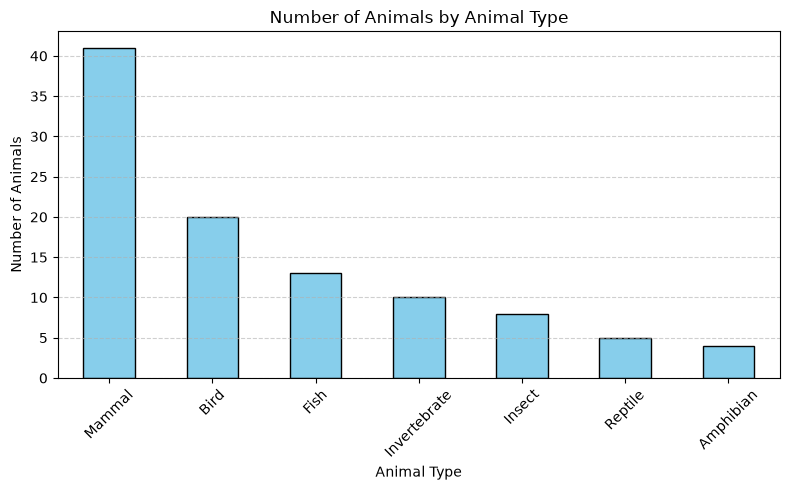

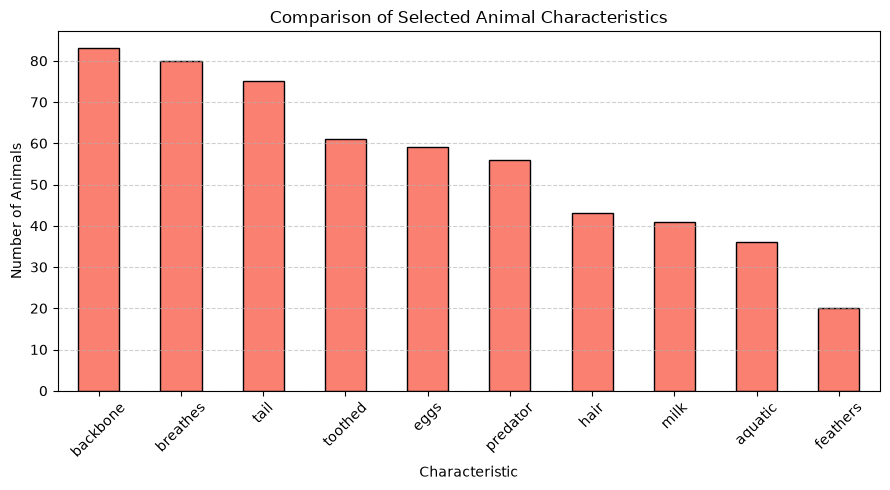

--- 3 OBSERVATIONS FROM THE DATASET ---
1. Mammal is the largest animal group with 41 records.
2. backbone is the most common characteristic, present in 83 animals.
3. There are 29 aquatic predators out of 36 aquatic animals in the dataset.

========== EDA COMPLETED SUCCESSFULLY ==========


In [1]:
# ============================================================
# ZOO DATASET - BASIC EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 2. LOAD THE DATASET FROM UCI REPOSITORY

columns = [
    "animal_name", "hair", "feathers", "eggs", "milk", "airborne",
    "aquatic", "predator", "toothed", "backbone", "breathes",
    "venomous", "fins", "legs", "tail", "domestic", "catsize", "class_type"
]

df = pd.read_csv(
    "zoo.data",
    names=columns
)

# Map class numbers to animal type names
class_names = {
    1: "Mammal",
    2: "Bird",
    3: "Reptile",
    4: "Fish",
    5: "Amphibian",
    6: "Insect",
    7: "Invertebrate"
}

df["animal_type"] = df["class_type"].map(class_names)


# ============================================================
# 3. BASIC DATASET INSPECTION
# ============================================================

print("--- FIRST 5 ROWS (HEAD) ---")
print(df.head(), "\n")

print("--- LAST 5 ROWS (TAIL) ---")
print(df.tail(), "\n")

print("--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- DATASET INFORMATION ---")
df.info()
print("\n")

print("--- STATISTICAL SUMMARY (DESCRIBE) ---")
print(df.describe(), "\n")


# ============================================================
# 4. MISSING VALUES AND DUPLICATES
# ============================================================

print("--- MISSING VALUES AND DUPLICATES ---")

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate animal names:", df["animal_name"].duplicated().sum())

print("\nDuplicate animal records:")
print(df[df["animal_name"].duplicated(keep=False)], "\n")


# ============================================================
# 5. ANIMAL COUNT PER TYPE
# ============================================================

print("--- ANIMAL COUNT PER TYPE ---")

type_counts = df["animal_type"].value_counts()

print(type_counts, "\n")

print("Animal types sorted by count:")
print(type_counts.sort_values(ascending=False), "\n")

print(f"Largest animal type: {type_counts.index[0]} "
      f"({type_counts.iloc[0]} animals)\n")


# ============================================================
# 6. COUNT ANIMAL CHARACTERISTICS
# ============================================================

print("--- COUNT OF ANIMAL CHARACTERISTICS ---")

traits = ["hair", "feathers", "eggs", "milk"]

for trait in traits:
    count = df[trait].sum()
    print(f"Animals with {trait}: {count}")

print("\n")


# ============================================================
# 7. AQUATIC PREDATORS
# ============================================================

print("--- AQUATIC PREDATORS ---")

aquatic_predators = df[
    (df["aquatic"] == 1) & (df["predator"] == 1)
]

print("Total aquatic predators:", len(aquatic_predators))

print("\nAnimals that are both aquatic and predators:")
print(
    aquatic_predators[["animal_name", "animal_type"]]
    .sort_values(by="animal_type")
    .to_string(index=False)
)

print("\n")


# ============================================================
# 8. MOST COMMON CHARACTERISTICS (NUMPY)
# ============================================================

print("--- MOST COMMON CHARACTERISTICS ---")

feature_cols = [
    "hair", "feathers", "eggs", "milk", "airborne", "aquatic",
    "predator", "toothed", "backbone", "breathes", "venomous",
    "fins", "tail", "domestic", "catsize"
]

# Convert selected features into a NumPy array
feature_matrix = df[feature_cols].to_numpy()

# Calculate characteristic counts using NumPy
trait_totals = np.sum(feature_matrix, axis=0)

# Calculate percentages
trait_percentages = np.round((trait_totals / len(df)) * 100, 2)

# Create summary table
summary_df = pd.DataFrame({
    "Characteristic": feature_cols,
    "Count": trait_totals,
    "Percentage (%)": trait_percentages
})

summary_df = summary_df.sort_values(by="Count", ascending=False)

print(summary_df.to_string(index=False), "\n")


# ============================================================
# 9. GROUPBY ANALYSIS
# ============================================================

print("--- AVERAGE LEGS BY ANIMAL TYPE ---")

average_legs = df.groupby("animal_type")["legs"].mean().round(2)

print(average_legs, "\n")


# ============================================================
# 10. SORTING ANIMALS BY NUMBER OF LEGS
# ============================================================

print("--- TOP 10 ANIMALS SORTED BY LEGS ---")

sorted_animals = df.sort_values(by="legs", ascending=False)

print(sorted_animals[["animal_name", "legs"]].head(10), "\n")


# ============================================================
# 11. CHART 1 - ANIMAL TYPE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

type_counts = df["animal_type"].value_counts()

type_counts.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Number of Animals by Animal Type")
plt.xlabel("Animal Type")
plt.ylabel("Number of Animals")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# ============================================================
# 12. CHART 2 - COMPARISON OF SELECTED CHARACTERISTICS
# ============================================================

plt.figure(figsize=(9, 5))

selected_traits = [
    "backbone", "breathes", "tail", "toothed", "eggs",
    "predator", "hair", "milk", "aquatic", "feathers"
]

selected_counts = df[selected_traits].sum()

selected_counts.plot(kind="bar", color="salmon", edgecolor="black")

plt.title("Comparison of Selected Animal Characteristics")
plt.xlabel("Characteristic")
plt.ylabel("Number of Animals")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# ============================================================
# 13. THREE OBSERVATIONS FROM THE DATASET
# ============================================================

print("--- 3 OBSERVATIONS FROM THE DATASET ---")

print(
    f"1. {type_counts.index[0]} is the largest animal group "
    f"with {type_counts.iloc[0]} records."
)

print(
    f"2. {summary_df.iloc[0]['Characteristic']} is the most common "
    f"characteristic, present in {summary_df.iloc[0]['Count']} animals."
)
 
aquatic_count = df["aquatic"].sum()

print(
    f"3. There are {len(aquatic_predators)} aquatic predators out of "
    f"{aquatic_count} aquatic animals in the dataset."
)

print("\n========== EDA COMPLETED SUCCESSFULLY ==========")